In [ ]:
import os
import shutil
import random
import zipfile
import json
import csv
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Zip
ZIP_PATH = "/content/drive/MyDrive/bitirme_son3/all_last7.zip"

PROJECT_DIR = "/content/drive/MyDrive/bitirme_son3/sadece_onler/sq_son"
EXTRACT_DIR = "/content/extracted_dataset"
PREPARED_DIR = "/content/prepared_dataset"

OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

MIN_IMAGES_PER_CLASS = 10
MAX_IMAGES_PER_CLASS = None

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15

IMG_SIZE = 192
BATCH_SIZE = 64
EPOCHS = 80
LR = 1e-3

# Resize
INTERPOLATION = "bilinear"

EXPORT_TEST_BIN = True

VALID_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)

PROJECT_DIR: /content/drive/MyDrive/bitirme_son3/sadece_onler/sq_son
OUTPUT_DIR: /content/drive/MyDrive/bitirme_son3/sadece_onler/sq_son/outputs


In [ ]:
if os.path.exists(EXTRACT_DIR):
    shutil.rmtree(EXTRACT_DIR)

os.makedirs(EXTRACT_DIR, exist_ok=True)

print("Zip açılıyor...")

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)

print("Zip açıldı:", EXTRACT_DIR)

Zip açılıyor...
Zip açıldı: /content/extracted_dataset


In [ ]:
def count_images_recursive(folder):
    count = 0
    for root, dirs, files in os.walk(folder):
        dirs[:] = [d for d in dirs if not d.startswith(".") and d != "__MACOSX"]
        for f in files:
            if f.lower().endswith(VALID_EXTS):
                count += 1
    return count


def find_dataset_root_any(extract_dir):
    """
    İçinde sınıf klasörleri olan ana dataset klasörünü otomatik bulur.
    Örnek beklenen yapı:
        dataset_root/
            class1/
            class2/
            class3/
    """
    candidates = []

    for root, dirs, files in os.walk(extract_dir):
        dirs[:] = [d for d in dirs if not d.startswith(".") and d != "__MACOSX"]

        class_like_dirs = []
        total_imgs = 0

        for d in dirs:
            p = os.path.join(root, d)
            c = count_images_recursive(p)

            if c > 0:
                class_like_dirs.append(d)
                total_imgs += c

        if len(class_like_dirs) >= 2 and total_imgs > 0:
            candidates.append((total_imgs, root, class_like_dirs))

    if not candidates:
        raise FileNotFoundError("Sınıf klasörleri bulunan dataset kökü bulunamadı.")

    candidates.sort(reverse=True, key=lambda x: x[0])
    total_imgs, root, class_dirs = candidates[0]

    return root, class_dirs, total_imgs


RAW_DATA_DIR, detected_classes, detected_total = find_dataset_root_any(EXTRACT_DIR)

print("Bulunan dataset ana klasörü:")
print(RAW_DATA_DIR)

print("\nBulunan sınıf klasörleri:")
for c in sorted(detected_classes):
    print("-", c)

print("\nToplam görüntü:", detected_total)

Bulunan dataset ana klasörü:
/content/extracted_dataset/all_last

Bulunan sınıf klasörleri:
- flies_back_leaf
- flies_leaf
- healthy_back_leaf
- healthy_leaf
- nutdef_back_leaf
- nutdef_leaf
- trips_back_leaf
- trips_leaf
- tuta_leaf

Toplam görüntü: 13627


In [ ]:
MIN_IMAGES_PER_CLASS = 10
all_class_counts = {}

for cls in sorted(os.listdir(RAW_DATA_DIR)):
    cls_path = os.path.join(RAW_DATA_DIR, cls)

    if not os.path.isdir(cls_path):
        continue

    if cls.startswith(".") or cls == "__MACOSX":
        continue

    count = count_images_recursive(cls_path)

    if count > 0:
        all_class_counts[cls] = count


print("Dataset içindeki tüm sınıflar:")
for cls, count in all_class_counts.items():
    print(f"{cls:25s} {count}")


TARGET_CLASSES = [
    "flies_leaf",
    "healthy_leaf",
    "nutdef_leaf",
    "trips_leaf",
    "tuta_leaf"
]

missing = [c for c in TARGET_CLASSES if c not in all_class_counts]
if missing:
    raise ValueError(f"Eksik sınıflar var: {missing}")

SELECTED_CLASSES = TARGET_CLASSES
SKIPPED_CLASSES = [
    cls for cls in all_class_counts.keys()
    if cls not in SELECTED_CLASSES
]

NUM_CLASSES = len(SELECTED_CLASSES)

print("\nSeçilen sınıflar:")
for cls in SELECTED_CLASSES:
    print(f"{cls:25s} {all_class_counts[cls]}")

print("\nAtlanan sınıflar:")
for cls in SKIPPED_CLASSES:
    print(f"{cls:25s} {all_class_counts[cls]}")

print("\nToplam seçilen sınıf sayısı:", NUM_CLASSES)

if NUM_CLASSES < 2:
    raise ValueError("Threshold çok yüksek. En az 2 sınıf kalmalı.")

Dataset içindeki tüm sınıflar:
flies_back_leaf           2322
flies_leaf                1997
healthy_back_leaf         1860
healthy_leaf              4325
nutdef_back_leaf          38
nutdef_leaf               943
trips_back_leaf           53
trips_leaf                1991
tuta_leaf                 98

Seçilen sınıflar:
flies_leaf                1997
healthy_leaf              4325
nutdef_leaf               943
trips_leaf                1991
tuta_leaf                 98

Atlanan sınıflar:
flies_back_leaf           2322
healthy_back_leaf         1860
nutdef_back_leaf          38
trips_back_leaf           53

Toplam seçilen sınıf sayısı: 5


In [ ]:
def list_images_recursive(folder):
    paths = []

    for root, dirs, files in os.walk(folder):
        dirs[:] = [d for d in dirs if not d.startswith(".") and d != "__MACOSX"]

        for f in files:
            if f.lower().endswith(VALID_EXTS):
                paths.append(os.path.join(root, f))

    return sorted(paths)


def safe_filename(class_name, idx, src_path):
    """
    Orijinal dosya adını tamamen öldürmüyoruz.
    Sonradan hata ayıklamak kolay olsun diye koruyoruz.
    """
    src_name = os.path.basename(src_path)
    name, ext = os.path.splitext(src_name)

    name = name.replace(" ", "_")
    name = name.replace("/", "_")
    name = name.replace("\\", "_")

    return f"{class_name}__{idx:06d}__{name}{ext.lower()}"


if os.path.exists(PREPARED_DIR):
    shutil.rmtree(PREPARED_DIR)

for split in ["train", "val", "test"]:
    for cls in SELECTED_CLASSES:
        os.makedirs(os.path.join(PREPARED_DIR, split, cls), exist_ok=True)


split_records = []
split_counts = {
    "train": {},
    "val": {},
    "test": {}
}

rng = random.Random(SEED)

for cls in SELECTED_CLASSES:
    src_dir = os.path.join(RAW_DATA_DIR, cls)

    files = list_images_recursive(src_dir)
    rng.shuffle(files)

    if MAX_IMAGES_PER_CLASS is not None and len(files) > MAX_IMAGES_PER_CLASS:
        files = files[:MAX_IMAGES_PER_CLASS]

    n = len(files)
    n_train = int(n * TRAIN_RATIO)
    n_val = int(n * VAL_RATIO)

    train_files = files[:n_train]
    val_files = files[n_train:n_train + n_val]
    test_files = files[n_train + n_val:]

    split_map = {
        "train": train_files,
        "val": val_files,
        "test": test_files
    }

    for split, split_files in split_map.items():
        split_counts[split][cls] = len(split_files)

        dst_cls_dir = os.path.join(PREPARED_DIR, split, cls)

        for idx, src_path in enumerate(split_files):
            dst_name = safe_filename(cls, idx, src_path)
            dst_path = os.path.join(dst_cls_dir, dst_name)

            shutil.copy2(src_path, dst_path)

            split_records.append({
                "split": split,
                "class": cls,
                "src_path": src_path,
                "dst_path": dst_path
            })


print("Split tamamlandı.")
print("PREPARED_DIR:", PREPARED_DIR)

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")
    total = 0
    for cls in SELECTED_CLASSES:
        c = split_counts[split][cls]
        total += c
        print(f"{cls:25s} {c}")
    print("Toplam:", total)


split_df = pd.DataFrame(split_records)
split_csv_path = os.path.join(OUTPUT_DIR, "split_records.csv")
split_df.to_csv(split_csv_path, index=False)

print("\nSplit kayıtları kaydedildi:")
print(split_csv_path)

Split tamamlandı.
PREPARED_DIR: /content/prepared_dataset

TRAIN
flies_leaf                1397
healthy_leaf              3027
nutdef_leaf               660
trips_leaf                1393
tuta_leaf                 68
Toplam: 6545

VAL
flies_leaf                299
healthy_leaf              648
nutdef_leaf               141
trips_leaf                298
tuta_leaf                 14
Toplam: 1400

TEST
flies_leaf                301
healthy_leaf              650
nutdef_leaf               142
trips_leaf                300
tuta_leaf                 16
Toplam: 1409

Split kayıtları kaydedildi:
/content/drive/MyDrive/bitirme_son3/sadece_onler/sq_son/outputs/split_records.csv


In [ ]:
train_dir = os.path.join(PREPARED_DIR, "train")
val_dir   = os.path.join(PREPARED_DIR, "val")
test_dir  = os.path.join(PREPARED_DIR, "test")


train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    class_names=SELECTED_CLASSES,
    image_size=(IMG_SIZE, IMG_SIZE),
    interpolation=INTERPOLATION,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    interpolation=INTERPOLATION,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    interpolation=INTERPOLATION,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)


class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("Class names:")
for i, c in enumerate(class_names):
    print(i, c)

print("NUM_CLASSES:", NUM_CLASSES)


labels_path = os.path.join(OUTPUT_DIR, "labels.txt")
with open(labels_path, "w", encoding="utf-8") as f:
    for c in class_names:
        f.write(c + "\n")

print("labels.txt kaydedildi:", labels_path)

Found 6545 files belonging to 5 classes.
Found 1400 files belonging to 5 classes.
Found 1409 files belonging to 5 classes.
Class names:
0 flies_leaf
1 healthy_leaf
2 nutdef_leaf
3 trips_leaf
4 tuta_leaf
NUM_CLASSES: 5
labels.txt kaydedildi: /content/drive/MyDrive/bitirme_son3/sadece_onler/sq_son/outputs/labels.txt


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

print("Datasetler hazır.")

Datasetler hazır.


In [ ]:
for images, labels in train_ds.take(1):
    print("Batch image shape:", images.shape)
    print("Batch label shape:", labels.shape)
    print("Image min:", tf.reduce_min(images).numpy())
    print("Image max:", tf.reduce_max(images).numpy())
    print("Label example:", labels[0].numpy())

Batch image shape: (64, 192, 192, 3)
Batch label shape: (64, 5)
Image min: 0.0
Image max: 255.0
Label example: [1. 0. 0. 0. 0.]


In [ ]:
def fire_module(x, squeeze_filters, expand_filters, name):
    """
    SqueezeNet'teki Fire Module fikri:
    1x1 squeeze
    sonra 1x1 expand + 3x3 expand
    """
    sq = layers.Conv2D(
        squeeze_filters,
        kernel_size=1,
        padding="same",
        use_bias=False,
        name=f"{name}_squeeze_1x1"
    )(x)
    sq = layers.BatchNormalization(name=f"{name}_squeeze_bn")(sq)
    sq = layers.ReLU(name=f"{name}_squeeze_relu")(sq)

    ex1 = layers.Conv2D(
        expand_filters,
        kernel_size=1,
        padding="same",
        use_bias=False,
        name=f"{name}_expand_1x1"
    )(sq)
    ex1 = layers.BatchNormalization(name=f"{name}_expand_1x1_bn")(ex1)
    ex1 = layers.ReLU(name=f"{name}_expand_1x1_relu")(ex1)

    ex3 = layers.Conv2D(
        expand_filters,
        kernel_size=3,
        padding="same",
        use_bias=False,
        name=f"{name}_expand_3x3"
    )(sq)
    ex3 = layers.BatchNormalization(name=f"{name}_expand_3x3_bn")(ex3)
    ex3 = layers.ReLU(name=f"{name}_expand_3x3_relu")(ex3)

    out = layers.Concatenate(name=f"{name}_concat")([ex1, ex3])

    return out


def build_fire_squeezenet_like(input_size, num_classes):
    inputs = layers.Input(shape=(input_size, input_size, 3), name="input_image")

    # Modelin içine koyuyoruz ki export ederken preprocessing unutulmasın
    x = layers.Rescaling(1.0 / 255.0, name="rescale_0_1")(inputs)

    # Hafif augmentation sadece training'de aktif olur
    x = layers.RandomFlip("horizontal", seed=SEED, name="aug_flip")(x)
    x = layers.RandomRotation(0.03, seed=SEED, name="aug_rotation")(x)
    #x = layers.RandomZoom(0.08, seed=SEED, name="aug_zoom")(x)
    x = layers.RandomContrast(0.10, seed=SEED, name="aug_contrast")(x)

    # Stem
    x = layers.Conv2D(32, kernel_size=3, strides=2, padding="same", use_bias=False, name="conv1")(x)
    x = layers.BatchNormalization(name="conv1_bn")(x)
    x = layers.ReLU(name="conv1_relu")(x)
    x = layers.MaxPooling2D(pool_size=3, strides=2, padding="same", name="pool1")(x)

    # Fire blokları
    x = fire_module(x, squeeze_filters=8,  expand_filters=24, name="fire2")
    x = fire_module(x, squeeze_filters=8,  expand_filters=24, name="fire3")
    x = layers.MaxPooling2D(pool_size=3, strides=2, padding="same", name="pool3")(x)

    x = fire_module(x, squeeze_filters=16, expand_filters=48, name="fire4")
    x = fire_module(x, squeeze_filters=16, expand_filters=48, name="fire5")
    x = layers.MaxPooling2D(pool_size=3, strides=2, padding="same", name="pool5")(x)

    x = fire_module(x, squeeze_filters=24, expand_filters=64, name="fire6")
    x = fire_module(x, squeeze_filters=24, expand_filters=64, name="fire7")

    x = layers.Dropout(0.35, name="dropout")(x)

    # Classifier
    x = layers.Conv2D(num_classes, kernel_size=1, padding="same", name="conv_logits")(x)
    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    outputs = layers.Softmax(name="predictions")(x)

    model = models.Model(inputs, outputs, name="fire_squeezenet_like")

    return model


model = build_fire_squeezenet_like(IMG_SIZE, NUM_CLASSES)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "fire_squeezenet_like"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 192, 192,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescale_0_1         │ (None, 192, 192,  │          0 │ input_image[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ aug_flip            │ (None, 192, 192,  │          0 │ rescale_0_1[0][0] │
│ (RandomFlip)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ aug_rotation        │ (None, 192, 192,  │          0 │ aug_flip[0][0]    │
│ (RandomRotation)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ aug_contrast        │ (None, 192, 192,  │          0 │ aug_rotation[0][… │
│ (RandomContrast)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1 (Conv2D)      │ (None, 96, 96,    │        864 │ aug_contrast[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 96, 96,    │        128 │ conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu (ReLU)   │ (None, 96, 96,    │          0 │ conv1_bn[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 48, 48,    │          0 │ conv1_relu[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire2_squeeze_1x1   │ (None, 48, 48, 8) │        256 │ pool1[0][0]       │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire2_squeeze_bn    │ (None, 48, 48, 8) │         32 │ fire2_squeeze_1x… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire2_squeeze_relu  │ (None, 48, 48, 8) │          0 │ fire2_squeeze_bn… │
│ (ReLU)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire2_expand_1x1    │ (None, 48, 48,    │        192 │ fire2_squeeze_re… │
│ (Conv2D)            │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire2_expand_3x3    │ (None, 48, 48,    │      1,728 │ fire2_squeeze_re… │
│ (Conv2D)            │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire2_expand_1x1_bn │ (None, 48, 48,    │         96 │ fire2_expand_1x1… │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire2_expand_3x3_bn │ (None, 48, 48,    │         96 │ fire2_expand_3x3… │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fire2_expand_1x1_r… │ (None, 48, 48,    │          0 │ fire2_expand_1x1

 Total params: 62,437 (243.89 KB)

 Trainable params: 61,093 (238.64 KB)

 Non-trainable params: 1,344 (5.25 KB)

In [ ]:
best_model_path = os.path.join(OUTPUT_DIR, "best_model.keras")
last_model_path = os.path.join(OUTPUT_DIR, "last_model.keras")

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        best_model_path,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=15,
        restore_best_weights=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

model.save(last_model_path)

print("Best model:", best_model_path)
print("Last model:", last_model_path)

Epoch 1/80
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 275ms/step - accuracy: 0.4660 - loss: 1.2726
Epoch 1: val_accuracy improved from None to 0.46286, saving model to /content/drive/MyDrive/bitirme_son3/sadece_onler/sq_son/outputs/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/bitirme_son3/sadece_onler/sq_son/outputs/best_model.keras
103/103 ━━━━━━━━━━━━━━━━━━━━ 56s 358ms/step - accuracy: 0.5277 - loss: 1.1446 - val_accuracy: 0.4629 - val_loss: 2.1828 - learning_rate: 0.0010
Epoch 2/80
102/103 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - accuracy: 0.6383 - loss: 0.9397
Epoch 2: val_accuracy did not improve from 0.46286
103/103 ━━━━━━━━━━━━━━━━━━━━ 34s 331ms/step - accuracy: 0.6655 - loss: 0.8846 - val_accuracy: 0.4629 - val_loss: 3.1322 - learning_rate: 0.0010
Epoch 3/80
102/103 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - accuracy: 0.7107 - loss: 0.7815
Epoch 3: val_accuracy did not improve from 0.46286
103/103 ━━━━━━━━━━━━━━━━━━━━ 41s 331ms/step - accuracy: 0.7348 - loss: 0.7279 - 

History kaydedildi: /content/drive/MyDrive/bitirme_son3/sadece_onler/sq_son/outputs/training_history.csv


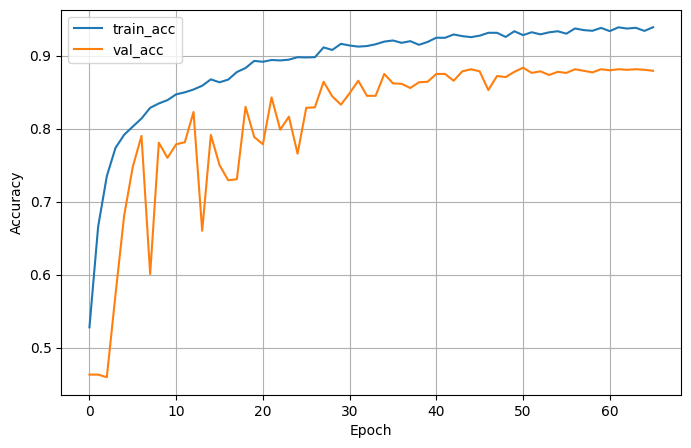

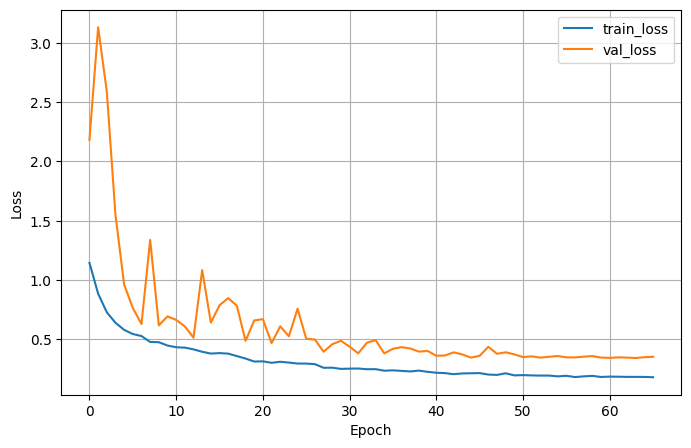

In [ ]:
history_df = pd.DataFrame(history.history)
history_csv_path = os.path.join(OUTPUT_DIR, "training_history.csv")
history_df.to_csv(history_csv_path, index=False)

print("History kaydedildi:", history_csv_path)

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="train_acc")
plt.plot(history.history["val_accuracy"], label="val_acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
best_model = tf.keras.models.load_model(best_model_path)

test_loss, test_acc = best_model.evaluate(test_ds, verbose=1)

print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 250ms/step - accuracy: 0.8829 - loss: 0.3340
Test loss: 0.3339725732803345
Test accuracy: 0.8828956484794617


In [ ]:
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = best_model.predict(images, verbose=0)

    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    output_dict=True
)

report_path = os.path.join(OUTPUT_DIR, "classification_report.json")
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report_dict, f, indent=4, ensure_ascii=False)

print("Classification report kaydedildi:", report_path)

              precision    recall  f1-score   support

  flies_leaf     0.8179    0.7608    0.7883       301
healthy_leaf     0.8873    0.9569    0.9208       650
 nutdef_leaf     0.9542    0.8803    0.9158       142
  trips_leaf     0.9011    0.8500    0.8748       300
   tuta_leaf     0.9286    0.8125    0.8667        16

    accuracy                         0.8829      1409
   macro avg     0.8978    0.8521    0.8733      1409
weighted avg     0.8826    0.8829    0.8816      1409

Classification report kaydedildi: /content/drive/MyDrive/bitirme_son3/sadece_onler/sq_son/outputs/classification_report.json


<Figure size 1000x1000 with 0 Axes>

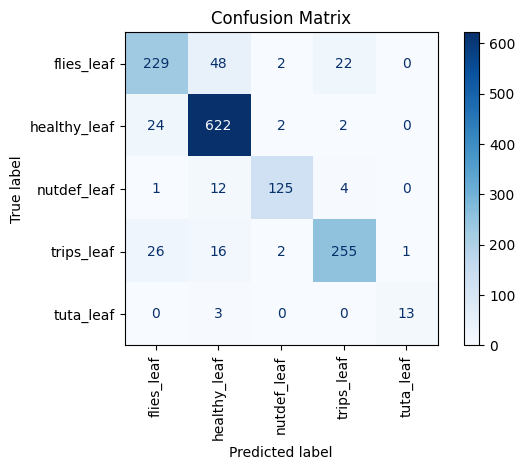

Confusion matrix kaydedildi: /content/drive/MyDrive/bitirme_son3/sadece_onler/sq_son/outputs/confusion_matrix.png


In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(xticks_rotation=90, cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.tight_layout()

cm_path = os.path.join(OUTPUT_DIR, "confusion_matrix.png")
plt.savefig(cm_path, dpi=200)
plt.show()

print("Confusion matrix kaydedildi:", cm_path)

In [ ]:
def representative_dataset():
    for images, labels in train_ds.take(100):
        yield [tf.cast(images, tf.float32)]


converter = tf.lite.TFLiteConverter.from_keras_model(best_model)

converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset

converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

# STM için genelde uint8 input/output daha rahat
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.uint8

tflite_quant = converter.convert()

tflite_path = os.path.join(OUTPUT_DIR, "model_uint8_quant.tflite")

with open(tflite_path, "wb") as f:
    f.write(tflite_quant)

print("Quantized TFLite kaydedildi:")
print(tflite_path)

print("TFLite size KB:", os.path.getsize(tflite_path) / 1024)

Saved artifact at '/tmp/tmp5nl5c9i7'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='input_image')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  132144640661200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132144640662160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132144640661968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132144640661584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132144640662736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132144640660816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132144640662352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132144640662544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132144640661008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132144640663696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132144640664080

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Quantized TFLite kaydedildi:
/content/drive/MyDrive/bitirme_son3/sadece_onler/sq_son/outputs/model_uint8_quant.tflite
TFLite size KB: 92.78125


In [ ]:
interpreter = tf.lite.Interpreter(model_path=tflite_path)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Input details:")
print(input_details)

print("\nOutput details:")
print(output_details)

Input details:
[{'name': 'serving_default_input_image:0', 'index': 0, 'shape': array([  1, 192, 192,   3], dtype=int32), 'shape_signature': array([ -1, 192, 192,   3], dtype=int32), 'dtype': <class 'numpy.uint8'>, 'quantization': (1.0, 0), 'quantization_parameters': {'scales': array([1.], dtype=float32), 'zero_points': array([0], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}]

Output details:
[{'name': 'StatefulPartitionedCall_1:0', 'index': 74, 'shape': array([1, 5], dtype=int32), 'shape_signature': array([-1,  5], dtype=int32), 'dtype': <class 'numpy.uint8'>, 'quantization': (0.00390625, 0), 'quantization_parameters': {'scales': array([0.00390625], dtype=float32), 'zero_points': array([0], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}]


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
def quantize_input_for_tflite(x_float, input_detail):
    dtype = input_detail["dtype"]
    scale, zero_point = input_detail["quantization"]

    if dtype == np.float32:
        return x_float.astype(np.float32)

    if scale == 0:
        raise ValueError("Input quantization scale 0 geldi.")

    x_q = np.round(x_float / scale + zero_point)

    if dtype == np.uint8:
        x_q = np.clip(x_q, 0, 255).astype(np.uint8)
    elif dtype == np.int8:
        x_q = np.clip(x_q, -128, 127).astype(np.int8)
    else:
        raise TypeError(f"Desteklenmeyen input dtype: {dtype}")

    return x_q


def dequantize_output_from_tflite(y, output_detail):
    dtype = output_detail["dtype"]
    scale, zero_point = output_detail["quantization"]

    if dtype == np.float32:
        return y.astype(np.float32)

    if scale == 0:
        return y.astype(np.float32)

    return scale * (y.astype(np.float32) - zero_point)


tflite_true = []
tflite_pred = []

for images, labels in test_ds:
    images_np = images.numpy()
    labels_np = labels.numpy()

    for i in range(images_np.shape[0]):
        x = images_np[i:i+1].astype(np.float32)

        x_q = quantize_input_for_tflite(x, input_details[0])

        interpreter.set_tensor(input_details[0]["index"], x_q)
        interpreter.invoke()

        y = interpreter.get_tensor(output_details[0]["index"])
        y = dequantize_output_from_tflite(y, output_details[0])

        pred_idx = int(np.argmax(y, axis=1)[0])
        true_idx = int(np.argmax(labels_np[i]))

        tflite_pred.append(pred_idx)
        tflite_true.append(true_idx)


tflite_true = np.array(tflite_true)
tflite_pred = np.array(tflite_pred)

tflite_acc = np.mean(tflite_true == tflite_pred)

print("TFLite quant test accuracy:", tflite_acc)

print(classification_report(
    tflite_true,
    tflite_pred,
    target_names=class_names,
    digits=4
))

TFLite quant test accuracy: 0.8836053938963804
              precision    recall  f1-score   support

  flies_leaf     0.8140    0.7708    0.7918       301
healthy_leaf     0.8931    0.9508    0.9210       650
 nutdef_leaf     0.9470    0.8803    0.9124       142
  trips_leaf     0.8955    0.8567    0.8756       300
   tuta_leaf     1.0000    0.8125    0.8966        16

    accuracy                         0.8836      1409
   macro avg     0.9099    0.8542    0.8795      1409
weighted avg     0.8833    0.8836    0.8826      1409



In [ ]:
if EXPORT_TEST_BIN:
    BIN_DIR = os.path.join(OUTPUT_DIR, "test_bins")
    os.makedirs(BIN_DIR, exist_ok=True)

    manifest = []

    input_detail = input_details[0]
    input_dtype = input_detail["dtype"]

    print("TFLite input dtype:", input_dtype)
    print("TFLite input quantization:", input_detail["quantization"])

    for class_idx, cls in enumerate(class_names):
        cls_test_dir = os.path.join(test_dir, cls)

        if not os.path.exists(cls_test_dir):
            continue

        out_cls_dir = os.path.join(BIN_DIR, cls)
        os.makedirs(out_cls_dir, exist_ok=True)

        image_files = [
            f for f in sorted(os.listdir(cls_test_dir))
            if f.lower().endswith(VALID_EXTS)
        ]

        for img_i, fname in enumerate(image_files):
            img_path = os.path.join(cls_test_dir, fname)

            img = tf.keras.utils.load_img(
                img_path,
                target_size=(IMG_SIZE, IMG_SIZE),
                interpolation=INTERPOLATION
            )

            arr = tf.keras.utils.img_to_array(img).astype(np.float32)
            arr = np.expand_dims(arr, axis=0)

            arr_q = quantize_input_for_tflite(arr, input_detail)
            arr_q = arr_q[0]

            bin_name = os.path.splitext(fname)[0] + ".bin"
            bin_path = os.path.join(out_cls_dir, bin_name)

            arr_q.tofile(bin_path)

            manifest.append({
                "class_name": cls,
                "class_idx": class_idx,
                "image_path": img_path,
                "bin_path": bin_path,
                "bin_name": bin_name,
                "shape": f"{IMG_SIZE}x{IMG_SIZE}x3",
                "dtype": str(input_dtype),
                "input_scale": input_detail["quantization"][0],
                "input_zero_point": input_detail["quantization"][1]
            })

    manifest_path = os.path.join(BIN_DIR, "manifest.csv")

    pd.DataFrame(manifest).to_csv(manifest_path, index=False)

    print("BIN dosyaları kaydedildi:")
    print(BIN_DIR)
    print("Manifest:")
    print(manifest_path)

NameError: name 'EXPORT_TEST_BIN' is not defined

In [ ]:
zip_output_path = os.path.join(PROJECT_DIR, "outputs.zip")

if os.path.exists(zip_output_path):
    os.remove(zip_output_path)

shutil.make_archive(
    base_name=zip_output_path.replace(".zip", ""),
    format="zip",
    root_dir=OUTPUT_DIR
)

print("Outputs zip kaydedildi:")
print(zip_output_path)

NameError: name 'os' is not defined